# Aligned FLIR v1 · the most confident detector errors, RGB vs thermal side by side, 2026-11-16

Follow-up to `aligned_backbone_results.ipynb` §6–§7. There, the RGB heads find objects (AP50 car ≈ 0.62) but their
boxes do not fit the shared ground truth (AP75/AP50 0.17–0.18 vs 0.46–0.48 for thermal). That points to an
**annotation problem**: one set of boxes, probably drawn on thermal, shared by both modalities.

This notebook looks at the evidence frame by frame. For one backbone, it takes the RGB head on the RGB frames and
the thermal head on the thermal frames (same frame ids, same boxes), labels every confident detection as a hit or
as a TIDE error type, and shows the frames where **the errors are the most confident on average**. A detector that
is very sure and still "wrong" is the best place to look for a bad label.

**Inputs, all read from `<repo>/outputs/`** (copied from the cluster's `$IRWM_OUTPUT_ROOT`):

| what | path under `outputs/` |
|---|---|
| F19 run JSON, test split (`align_validation`, 1,013 pairs) | `detection/2026-11-16/17-54-19_slurm-5532481/eval_aligned.json` |
| F19 run JSON, val split (413 pairs) | `detection/2026-11-16/17-54-19_slurm-5532482/eval_aligned.json` |
| saved detections (in-domain cells only are used) | `detection/detections/<encoder_tag>/<head>/<modality>_<split>.json.gz` |

Both runs: `bash slurm/eval_aligned.sh ctcomp3 [split=val]`, git `11ccb4d` (clean), NVIDIA L4 (hpc-gpu6).
The notebook finds the run JSON for `SPLIT`, opens the detection files it lists, checks their SHA-256, and checks that
its own AP50 (via `tide()`) equals the AP50 recorded in the run. If `outputs/` has no run for `SPLIT` it falls back
to `$IRWM_OUTPUT_ROOT`. The GT and the pixels are not outputs: they come from the local aligned dataset
(`$IRWM_DATA_ROOT/aligned/align/`).

In [1]:
import gzip
import hashlib
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from PIL import Image

from irwm.data.aligned import AlignedSplit
from irwm.eval.tide import _Data, _evaluate, box_iou, tide
from irwm.utils.paths import load_env, output_root, repo_root

load_env()  # IRWM_DATA_ROOT for the GT and the pixels

# ---- parameters
BACKBONE = "dinopca"  # dinopca | dino3072 | mae: the pair of heads aligned_<BACKBONE>_{rgb,ir}
SPLIT = "test"        # test (align_validation, held out) | val (the selection split)
SCORE_MIN = 0.4       # a detection counts (is drawn, can be an error) only at score >= SCORE_MIN
TOP_N = 12            # frames shown per ranking
MIN_ERRORS = 1        # a frame needs at least this many confident errors to be ranked
POS_THR, BG_THR, MAX_DETS = 0.5, 0.1, 100  # TIDE / COCO settings (as in irwm.eval.tide)

MODS = ["rgb", "ir"]
SPLIT_MOD = {"rgb": "rgb", "ir": "thermal"}  # head suffix -> AlignedSplit modality
HEAD = {m: f"aligned_{BACKBONE}_{m}" for m in MODS}
MOD_LABEL = {"rgb": "RGB", "ir": "Thermal"}
CAT_NAME = {1: "person", 2: "car"}


def find_run(root, split):
    # the latest F19 run (eval_aligned.json, mode=run) on `split` under root/detection/<date>/<time>/
    runs = []
    for p in sorted((root / "detection").glob("*/*/eval_aligned.json")):
        r = json.loads(p.read_text())
        if r.get("mode") == "run" and r.get("split") == split and r.get("dataset") == "aligned_v1":
            runs.append((r["created_at"], p, r))
    return max(runs, key=lambda t: t[0])[1:] if runs else (None, None)


# Everything comes from <repo>/outputs (cluster outputs copied back); $IRWM_OUTPUT_ROOT only if it has no run.
OUT = repo_root() / "outputs"
RUN_PATH, RUN = find_run(OUT, SPLIT)
if RUN is None:
    OUT = output_root()
    RUN_PATH, RUN = find_run(OUT, SPLIT)
assert RUN is not None, f"no F19 eval_aligned.json for split={SPLIT} under <repo>/outputs or $IRWM_OUTPUT_ROOT"
assert all(HEAD[m] in RUN["heads"] for m in MODS), (list(RUN["heads"]), HEAD)

SPL, GT, DETS, FILES = {}, {}, {}, {}
for m in MODS:
    SPL[m] = AlignedSplit.load(SPLIT_MOD[m], SPLIT)
    GT[m] = SPL[m].to_coco_gt()
    entry = RUN["detections"][HEAD[m]][SPLIT_MOD[m]]  # path is relative to the output root
    FILES[m] = OUT / entry["path"]
    raw = FILES[m].read_bytes()
    assert hashlib.sha256(raw).hexdigest() == entry["sha256"], f"{FILES[m]} differs from the run's SHA-256"
    obj = json.loads(gzip.decompress(raw))
    assert (obj["head"], obj["modality"], obj["split"], obj["dataset"]) == \
        (HEAD[m], SPLIT_MOD[m], SPLIT, "aligned_v1"), FILES[m]
    assert obj["n_images"] == len(GT[m]["images"]) == entry["n_images"], FILES[m]
    assert len(obj["detections"]) == entry["n_detections"], FILES[m]
    DETS[m] = obj["detections"]

# The two modalities must share frame ids and boxes, otherwise "side by side" means nothing.
assert [r.image_id for r in SPL["rgb"]] == [r.image_id for r in SPL["ir"]]
assert all(np.array_equal(a.boxes, b.boxes) for a, b in zip(SPL["rgb"], SPL["ir"]))

dev = RUN["device"]
print(f"output root : {OUT}")
print(f"F19 run     : {RUN_PATH.relative_to(OUT)}  (split={RUN['split']}, git {RUN['git']['commit'][:7]}"
      f"{' dirty' if RUN['git']['dirty'] else ''}, {dev['name']} on {dev['slurm_node']}, SLURM {dev['slurm_job_id']})")
for m in MODS:
    h = RUN["heads"][HEAD[m]]
    print(f"{HEAD[m]:22s} {SPLIT_MOD[m]}_{SPLIT}: {len(DETS[m]):,} detections on {len(GT[m]['images'])} frames, "
          f"best epoch {h['epoch']}, sha256 ok  ({FILES[m].relative_to(OUT)})")

output root : /home/leonardo.ulloa/projects/ir-world-model/outputs
F19 run     : detection/2026-11-16/17-54-19_slurm-5532481/eval_aligned.json  (split=test, git 11ccb4d, NVIDIA L4 on hpc-gpu6, SLURM 5532481)
aligned_dinopca_rgb    rgb_test: 303,900 detections on 1013 frames, best epoch 16, sha256 ok  (detection/detections/dinov2_vitb14reg_448x560_l3-6-9-12_pca1152/aligned_dinopca_rgb/rgb_test.json.gz)
aligned_dinopca_ir     thermal_test: 303,900 detections on 1013 frames, best epoch 16, sha256 ok  (detection/detections/dinov2_vitb14reg_448x560_l3-6-9-12_pca1152/aligned_dinopca_ir/thermal_test.json.gz)


## 0. Ground truth only: thermal next to RGB

No detections needed. The one shared annotation of each pair drawn on the thermal frame (left) and the RGB frame
(right), large, to look at how well the same box fits each modality. Person cyan, car yellow.

`GT_IDS = [...]` picks frames by id; left empty, `GT_N` frames are taken evenly spaced over the split among frames
with at least one box.

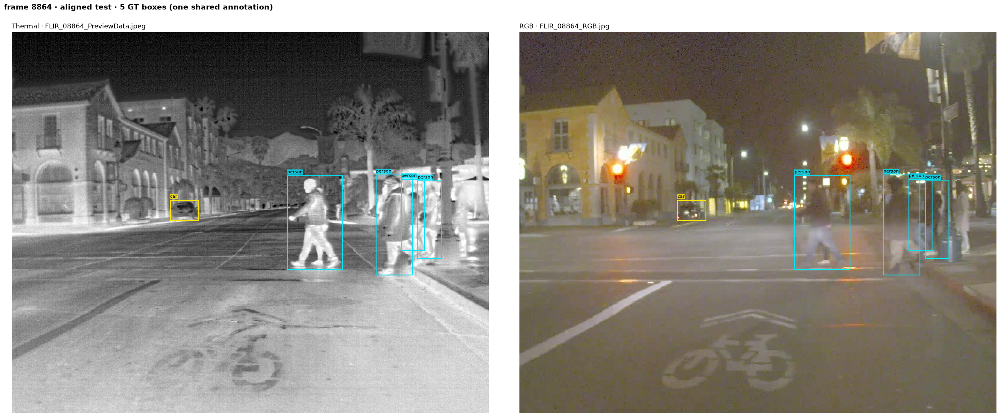

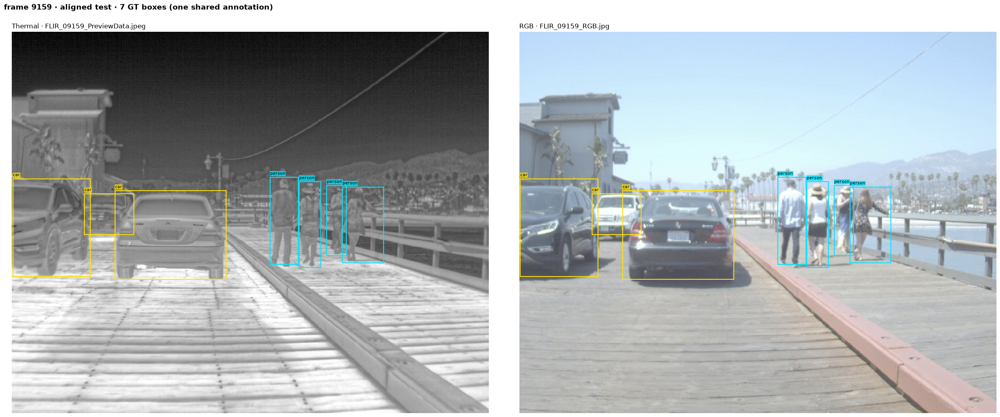

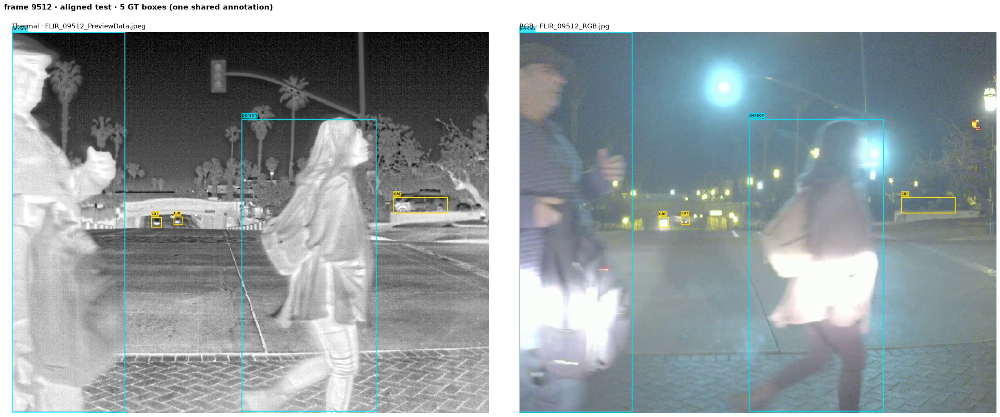

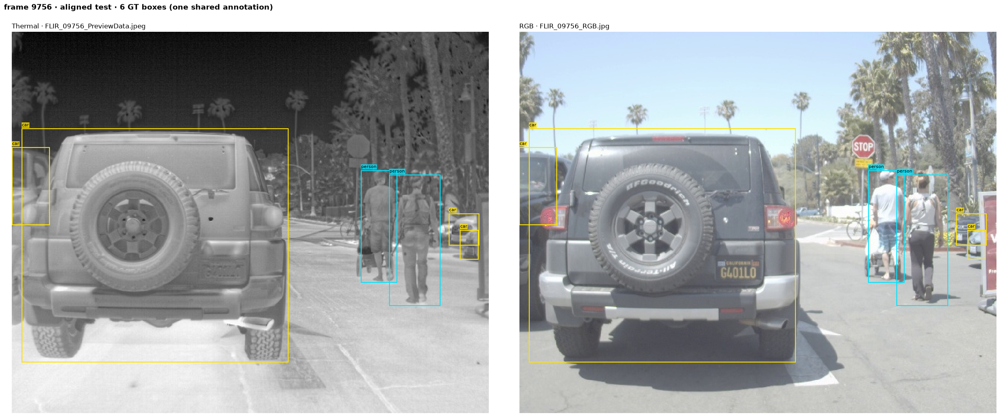

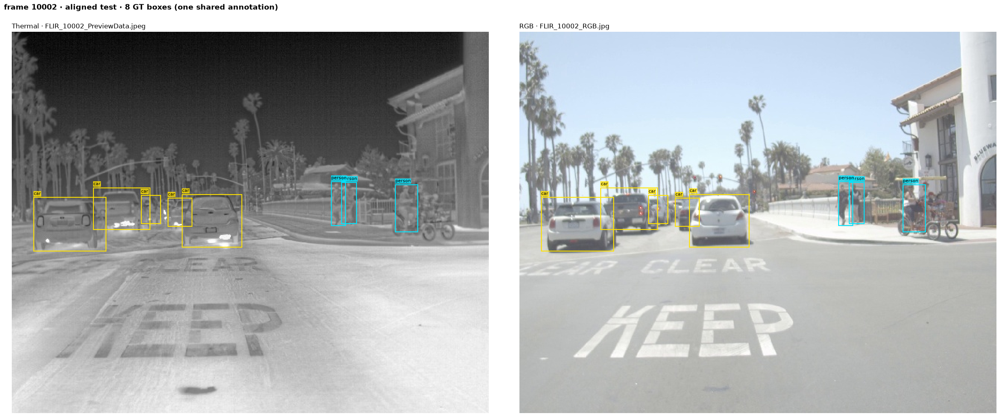

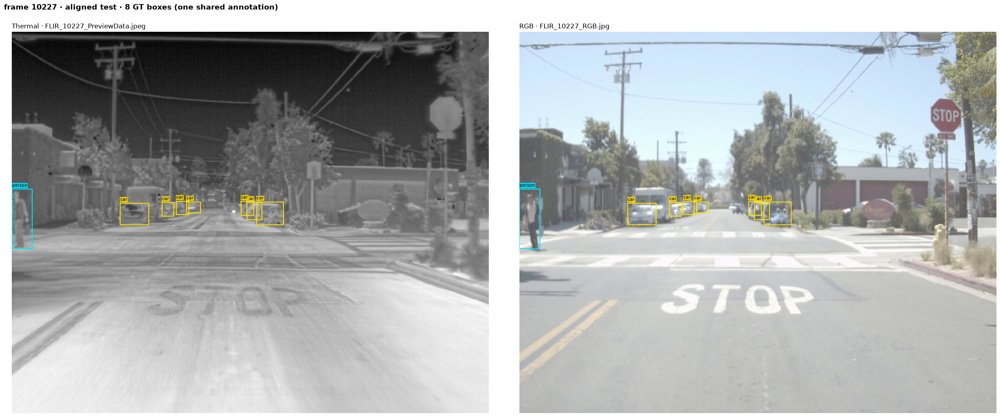

In [2]:
GT_IDS = []        # e.g. [8882, 9845]; empty -> GT_N evenly spaced frames
GT_N = 6
GT_FIGSIZE = (26, 10.8)  # two 640x512 frames side by side; one pair per figure
GT_EDGE = {0: "#00e5ff", 1: "#ffe100"}  # person cyan, car yellow (as aligned_backbone_results.ipynb)
GT_NAME = {0: "person", 1: "car"}


def show_gt_pair(iid):
    fig, axes = plt.subplots(1, 2, figsize=GT_FIGSIZE)
    for ax, m in zip(axes, ("ir", "rgb")):
        rec = SPL[m].by_image_id(iid)
        ax.imshow(Image.open(rec.path).convert("RGB"), interpolation="nearest")
        for (x0, y0, w, h), lab in zip(rec.boxes, rec.labels):
            ax.add_patch(plt.Rectangle((x0, y0), w, h, fill=False, lw=1.6, ec=GT_EDGE[int(lab)]))
            ax.text(x0, y0 - 2, GT_NAME[int(lab)], color="black", fontsize=8, va="bottom",
                    bbox=dict(boxstyle="square,pad=0.1", fc=GT_EDGE[int(lab)], ec="none", alpha=0.8))
        ax.set_axis_off()
        ax.set_title(f"{MOD_LABEL[m]} · {rec.file_name.split('/')[-1]}", loc="left", fontsize=12)
    fig.suptitle(f"frame {iid} · aligned {SPLIT} · {len(rec.boxes)} GT boxes (one shared annotation)",
                 x=0.01, ha="left", fontsize=14, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()


ids = GT_IDS or (lambda c: [c[k] for k in np.linspace(0, len(c) - 1, GT_N).astype(int)])(
    [r.image_id for r in SPL["ir"] if len(r.boxes)])
for iid in ids:
    show_gt_pair(iid)

## 1. Label every detection

Each detection gets the outcome TIDE gives it (`irwm.eval.tide`, same COCO matching: per class, by score, IoU 0.5,
at most 100 detections per frame and class):

| outcome | meaning | what it suggests about the label |
|---|---|---|
| **TP** | matched a GT box at IoU ≥ 0.5 | – |
| **Loc** | right class, best IoU with a GT box in [0.1, 0.5) | the box is offset/mis-sized: **box geometry** |
| **Bkg** | IoU < 0.1 with every GT box | nothing annotated there: **missing label** (or a real false alarm) |
| **Cls** | IoU ≥ 0.5 with a GT box of the other class | person/car confusion, or a wrong label |
| **Dupe** | its GT box was already taken by a higher-scoring detection | detector issue, not a label one |
| **Both** | wrong class and a bad box | – |

The labelling runs on *all* detections, like TIDE, so the per-type counts can be checked against `tide()`. Only
detections with score ≥ `SCORE_MIN` are then used for the ranking and drawn.

In [3]:
def label_detections(gt, detections):
    # -> (records, missed): one dict per detection kept by the COCO matching, and the GT TIDE calls Miss.
    data = _Data(gt, detections, MAX_DETS)
    _, matches = _evaluate(data.gt, data.dt, data.img_ids, data.cats, POS_THR)
    recs, targeted = [], {i: np.zeros(len(data.gt[i][0]), bool) for i in data.img_ids}
    used = {i: np.zeros(len(data.gt[i][0]), bool) for i in data.img_ids}
    for (i, c), (s, b) in data.dt.items():
        dt_gt, dt_ig = matches[(i, c)]
        used[i][dt_gt[dt_gt >= 0]] = True
        g_lab, g_box, g_crowd = data.gt[i]
        iou = box_iou(b, g_box)
        same, other, real = (g_lab == c) & ~g_crowd, (g_lab != c) & ~g_crowd, ~g_crowd
        for d in range(len(s)):
            target = -1
            if dt_ig[d]:
                continue
            if dt_gt[d] >= 0:
                kind, target = "TP", int(dt_gt[d])
            else:  # same order of checks as irwm.eval.tide.tide
                row = iou[d]
                m_same = row[same].max() if same.any() else 0.0
                m_other = row[other].max() if other.any() else 0.0
                m_all = row[real].max() if real.any() else 0.0
                if BG_THR <= m_same < POS_THR:
                    kind, target = "Loc", int(np.flatnonzero(same)[row[same].argmax()])
                elif m_other >= POS_THR:
                    kind, target = "Cls", int(np.flatnonzero(other)[row[other].argmax()])
                elif m_same >= POS_THR:
                    kind = "Dupe"
                elif m_all < BG_THR:
                    kind = "Bkg"
                else:
                    kind = "Both"
                if target >= 0:
                    targeted[i][target] = True
            recs.append({"image_id": i, "category_id": c, "score": float(s[d]), "bbox": b[d], "kind": kind,
                         "gt": target, "iou": float(iou[d].max()) if iou.shape[1] else 0.0})
    missed = {i: ~used[i] & ~data.gt[i][2] & ~targeted[i] for i in data.img_ids}
    return recs, missed


ERR_TYPES = ["Loc", "Bkg", "Cls", "Dupe", "Both"]
REC, MISSED, TIDE = {}, {}, {}
for m in DETS:
    REC[m], MISSED[m] = label_detections(GT[m], DETS[m])
    TIDE[m] = tide(GT[m], DETS[m], pos_thr=POS_THR, bg_thr=BG_THR, max_dets=MAX_DETS)
    n = Counter(r["kind"] for r in REC[m])
    # cross-check: the labelling reproduces TIDE's own counts exactly
    assert all(n[k] == TIDE[m].counts[k] for k in ERR_TYPES), (m, n, TIDE[m].counts)
    assert n["TP"] == TIDE[m].counts["TP"], (m, n["TP"], TIDE[m].counts["TP"])
    assert sum(int(v.sum()) for v in MISSED[m].values()) == TIDE[m].counts["Miss"], m
    ap50_run = RUN["cells"][HEAD[m]][SPLIT_MOD[m]]["AP50_person_car"]
    assert abs(TIDE[m].ap50 - ap50_run) < 1e-9, (m, TIDE[m].ap50, ap50_run)  # same matching as coco_map
    print(f"{HEAD[m]:22s} AP50 {TIDE[m].ap50:.3f} (= F19 run {ap50_run:.3f})   labelled counts match tide(): ok")

rows = []
for m in REC:
    conf = [r for r in REC[m] if r["score"] >= SCORE_MIN]
    n = Counter(r["kind"] for r in conf)
    errs = [r for r in conf if r["kind"] != "TP"]
    rows.append([MOD_LABEL[m], len(conf), n["TP"], len(errs)] + [n[k] for k in ERR_TYPES]
                + [f"{np.mean([r['score'] for r in errs]):.3f}" if errs else "–",
                   f"{np.mean([r['iou'] for r in conf if r['kind'] == 'TP']):.3f}" if n["TP"] else "–"])
if rows:
    hdr = ["head (own modality)", f"dets ≥ {SCORE_MIN}", "TP", "errors"] + ERR_TYPES + ["mean error score",
                                                                                          "mean TP IoU"]
    display(Markdown(f"**Confident detections (score ≥ {SCORE_MIN}), aligned {SPLIT}, backbone `{BACKBONE}`**"))
    display(Markdown("\n".join(["| " + " | ".join(hdr) + " |", "|" + "---|" * len(hdr)]
                               + ["| " + " | ".join(str(v) for v in r) + " |" for r in rows])))

aligned_dinopca_rgb    AP50 0.703 (= F19 run 0.703)   labelled counts match tide(): ok


aligned_dinopca_ir     AP50 0.802 (= F19 run 0.802)   labelled counts match tide(): ok


**Confident detections (score ≥ 0.4), aligned test, backbone `dinopca`**

| head (own modality) | dets ≥ 0.4 | TP | errors | Loc | Bkg | Cls | Dupe | Both | mean error score | mean TP IoU |
|---|---|---|---|---|---|---|---|---|---|---|
| RGB | 7486 | 5413 | 2073 | 789 | 1025 | 3 | 207 | 49 | 0.559 | 0.764 |
| Thermal | 8545 | 6338 | 2207 | 686 | 1206 | 4 | 269 | 42 | 0.559 | 0.782 |

## 2. Rank frames by the mean confidence of their errors

For each frame and head: the confident errors (score ≥ `SCORE_MIN`, outcome ≠ TP) and their **mean score**.
Three rankings:

- **both**: the errors of both heads pooled, so a frame scores high when either head is confidently wrong;
- **rgb**: only the RGB head's errors; **ir**: only the thermal head's errors.

A frame needs at least `MIN_ERRORS` confident errors in the ranked set to enter the ranking.

In [4]:
IMG_IDS = [r.image_id for r in SPL["rgb"]]
ERRS = {m: {i: [] for i in IMG_IDS} for m in REC}
for m in REC:
    for r in REC[m]:
        if r["score"] >= SCORE_MIN and r["kind"] != "TP":
            ERRS[m][r["image_id"]].append(r)


def ranking(by):
    mods = list(REC) if by == "both" else [by]
    if not all(m in REC for m in mods):
        return []
    out = []
    for i in IMG_IDS:
        errs = [r for m in mods for r in ERRS[m][i]]
        if len(errs) >= MIN_ERRORS:
            out.append((float(np.mean([r["score"] for r in errs])), len(errs), i))
    return sorted(out, key=lambda t: (-t[0], -t[1], t[2]))


def type_summary(errs):
    n = Counter(r["kind"] for r in errs)
    return " ".join(f"{k}:{n[k]}" for k in ERR_TYPES if n[k]) or "–"


def show_ranking_table(by):
    rk = ranking(by)[:TOP_N]
    if not rk:
        print(f"{by}: nothing to rank (missing detections or no confident errors)")
        return []
    hdr = ["rank", "frame id", f"mean error score ({by})", "# errors"]
    for m in REC:
        hdr += [f"{MOD_LABEL[m]} errors (mean score)", f"{MOD_LABEL[m]} types"]
    rows = []
    for k, (mean, n, i) in enumerate(rk, 1):
        row = [k, i, f"{mean:.3f}", n]
        for m in REC:
            e = ERRS[m][i]
            row += [f"{len(e)} ({np.mean([r['score'] for r in e]):.2f})" if e else "0", type_summary(e)]
        rows.append(row)
    display(Markdown("\n".join(["| " + " | ".join(hdr) + " |", "|" + "---|" * len(hdr)]
                               + ["| " + " | ".join(str(v) for v in r) + " |" for r in rows])))
    return [i for _, _, i in rk]


for by in ("both", "rgb", "ir"):
    n = len(ranking(by))
    print(f"{by:5s}: {n} frames with ≥ {MIN_ERRORS} confident error(s) out of {len(IMG_IDS)}")

both : 946 frames with ≥ 1 confident error(s) out of 1013
rgb  : 816 frames with ≥ 1 confident error(s) out of 1013
ir   : 841 frames with ≥ 1 confident error(s) out of 1013


## 3. Side by side

Left: the RGB frame with the **RGB head's** detections. Right: the thermal frame with the **thermal head's**
detections. Same frame id, same ground truth on both sides.

- **Ground truth**: thin white dashed boxes; a GT box that no confident TP matched is drawn **red dashed** (missed
  at `SCORE_MIN`).
- **Detections** (score ≥ `SCORE_MIN`), solid, labelled `outcome class score`: TP green, Loc orange, Bkg magenta,
  Cls blue, Dupe/Both grey. For Loc/Cls errors a thin line joins the box to the GT box it was matched to.

In [5]:
KIND_COLOR = {"TP": "#22c55e", "Loc": "#ff9f1a", "Bkg": "#ff2bd6", "Cls": "#3b82f6", "Dupe": "#a3a3a3",
              "Both": "#a3a3a3"}
GT_COLOR, MISS_COLOR = "#ffffff", "#ff3030"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9.5})


def draw(ax, m, iid):
    rec = SPL[m].by_image_id(iid)
    ax.imshow(Image.open(rec.path).convert("RGB"))
    ax.set_axis_off()
    gt_boxes = np.asarray(rec.boxes, float).reshape(-1, 4)
    dets = sorted([r for r in REC.get(m, []) if r["image_id"] == iid and r["score"] >= SCORE_MIN],
                  key=lambda r: r["score"])  # highest score drawn last (on top)
    hit = np.zeros(len(gt_boxes), bool)
    for r in dets:
        if r["kind"] == "TP":
            hit[r["gt"]] = True
    for k, (x0, y0, w, h) in enumerate(gt_boxes):
        ax.add_patch(plt.Rectangle((x0, y0), w, h, fill=False, lw=1.6 if not hit[k] else 0.9, ls="--",
                                   ec=MISS_COLOR if not hit[k] else GT_COLOR))
    for r in dets:
        x0, y0, w, h = r["bbox"]
        col = KIND_COLOR[r["kind"]]
        ax.add_patch(plt.Rectangle((x0, y0), w, h, fill=False, lw=1.5, ec=col))
        if r["kind"] in ("Loc", "Cls") and r["gt"] >= 0:
            gx, gy, gw, gh = gt_boxes[r["gt"]]
            ax.plot([x0 + w / 2, gx + gw / 2], [y0 + h / 2, gy + gh / 2], color=col, lw=0.8)
        ax.text(x0, y0 - 2, f"{r['kind']} {CAT_NAME[r['category_id']]} {r['score']:.2f}", color="black",
                fontsize=6.5, va="bottom", bbox=dict(boxstyle="square,pad=0.1", fc=col, ec="none", alpha=0.85))
    e = ERRS.get(m, {}).get(iid, [])
    err_txt = f"{len(e)} errors, mean {np.mean([r['score'] for r in e]):.2f} ({type_summary(e)})" if e else "0 errors"
    tp = sum(r["kind"] == "TP" for r in dets)
    ax.set_title(f"{MOD_LABEL[m]} · {HEAD[m]} · {tp} TP · {err_txt}\n"
                 f"GT {len(gt_boxes)} boxes, {int((~hit).sum())} missed at score ≥ {SCORE_MIN}", loc="left")


LEGEND = ([Line2D([], [], color=KIND_COLOR[k], lw=2, label=k) for k in ("TP", "Loc", "Bkg", "Cls", "Dupe")]
          + [Line2D([], [], color="#555555", lw=1, ls="--", label="GT (white on image)"),
             Line2D([], [], color=MISS_COLOR, lw=1.5, ls="--", label="GT missed")])


def show_pairs(ids, by):
    for k, iid in enumerate(ids, 1):
        fig, axes = plt.subplots(1, 2, figsize=(14, 5.9))
        for ax, m in zip(axes, MODS):
            draw(ax, m, iid)
        mean = next(t[0] for t in ranking(by) if t[2] == iid)
        fig.suptitle(f"#{k} by '{by}' · frame {iid} ({SPL['rgb'].by_image_id(iid).file_name.split('/')[-1]}) · "
                     f"mean error score {mean:.3f}", x=0.01, ha="left", fontweight="bold")
        if k == 1:
            fig.legend(handles=LEGEND, loc="lower center", ncol=len(LEGEND), frameon=False, fontsize=8)
        fig.tight_layout(rect=(0, 0.04 if k == 1 else 0, 1, 0.95))
        plt.show()

### 3.1 Ranked by both heads' errors (pooled)

| rank | frame id | mean error score (both) | # errors | RGB errors (mean score) | RGB types | Thermal errors (mean score) | Thermal types |
|---|---|---|---|---|---|---|---|
| 1 | 9262 | 0.914 | 1 | 1 (0.91) | Loc:1 | 0 | – |
| 2 | 10135 | 0.909 | 1 | 0 | – | 1 (0.91) | Loc:1 |
| 3 | 9611 | 0.895 | 1 | 1 (0.90) | Loc:1 | 0 | – |
| 4 | 9549 | 0.855 | 1 | 0 | – | 1 (0.85) | Loc:1 |
| 5 | 8926 | 0.826 | 1 | 1 (0.83) | Loc:1 | 0 | – |
| 6 | 9352 | 0.820 | 1 | 1 (0.82) | Loc:1 | 0 | – |
| 7 | 9615 | 0.817 | 6 | 5 (0.81) | Loc:4 Bkg:1 | 1 (0.87) | Bkg:1 |
| 8 | 9826 | 0.816 | 1 | 0 | – | 1 (0.82) | Loc:1 |
| 9 | 9834 | 0.815 | 1 | 1 (0.82) | Bkg:1 | 0 | – |
| 10 | 9858 | 0.809 | 3 | 2 (0.77) | Loc:1 Bkg:1 | 1 (0.89) | Loc:1 |
| 11 | 9414 | 0.808 | 3 | 1 (0.90) | Loc:1 | 2 (0.76) | Loc:1 Bkg:1 |
| 12 | 9892 | 0.807 | 2 | 1 (0.75) | Bkg:1 | 1 (0.87) | Bkg:1 |

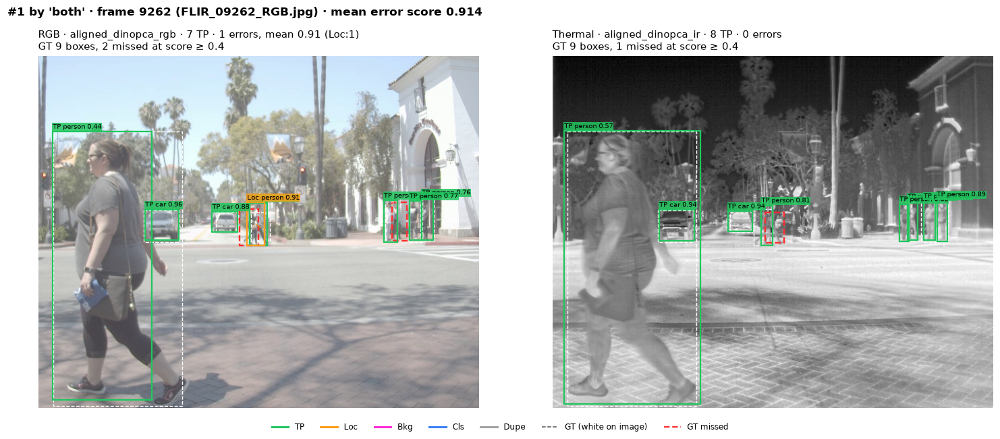

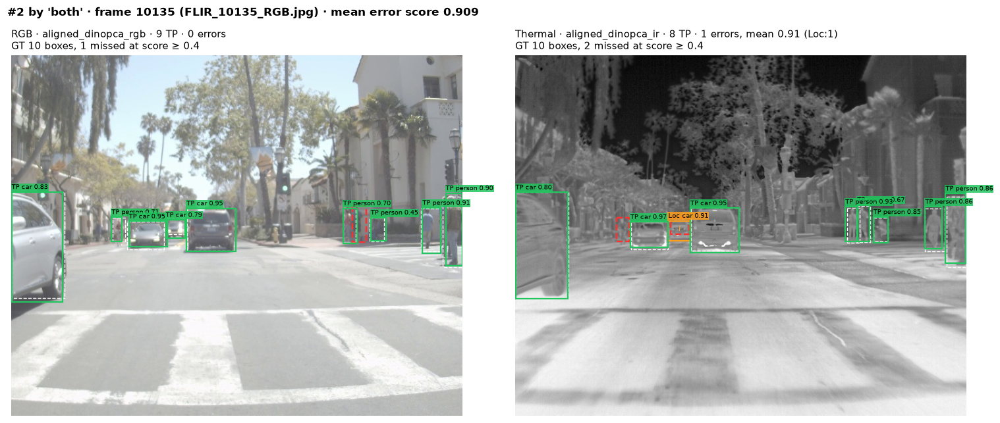

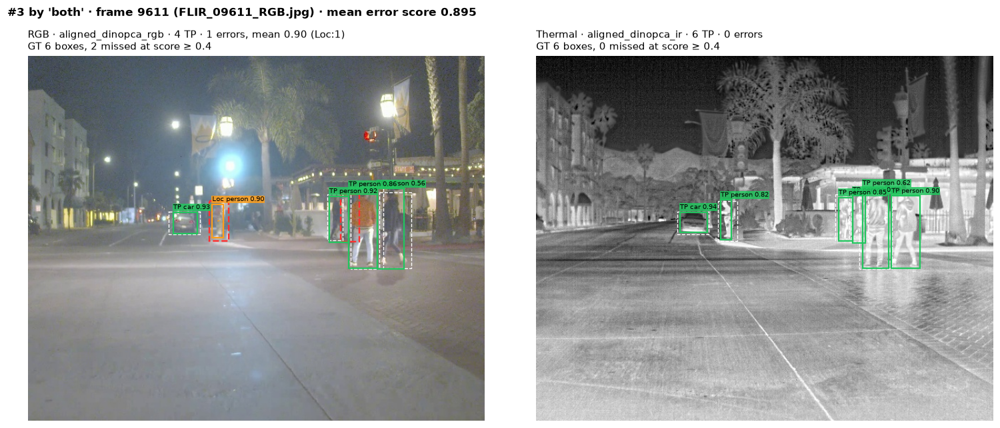

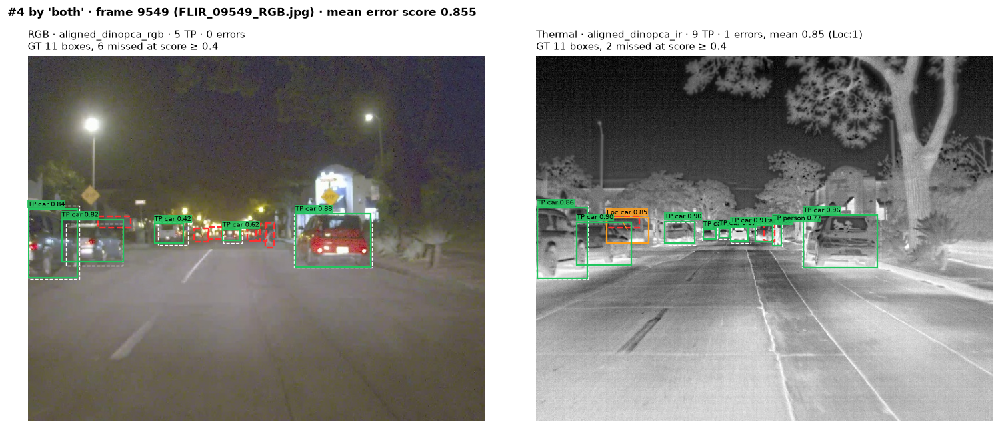

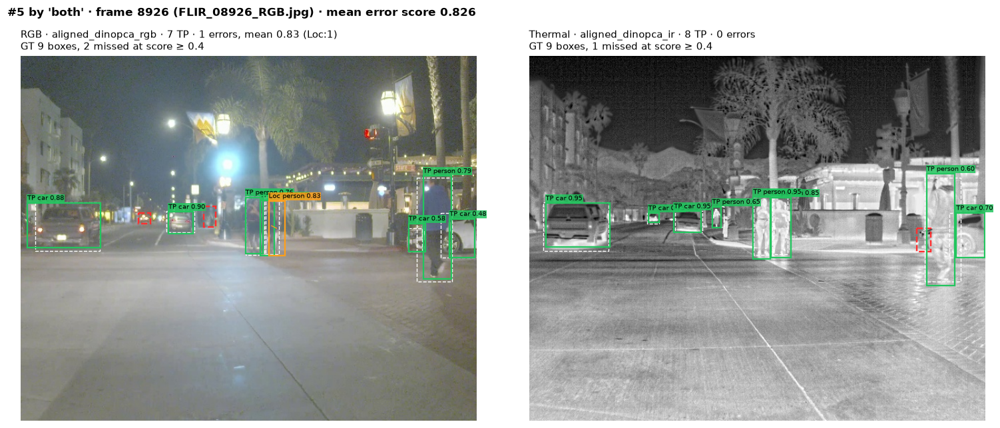

...

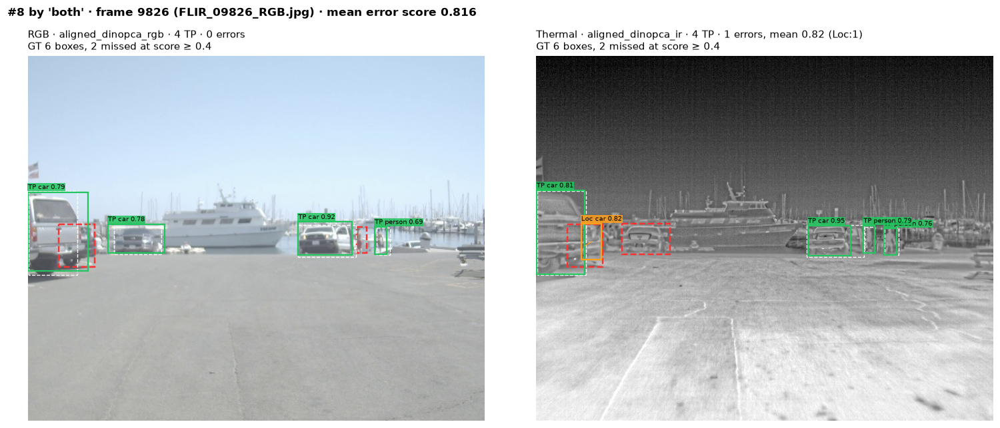

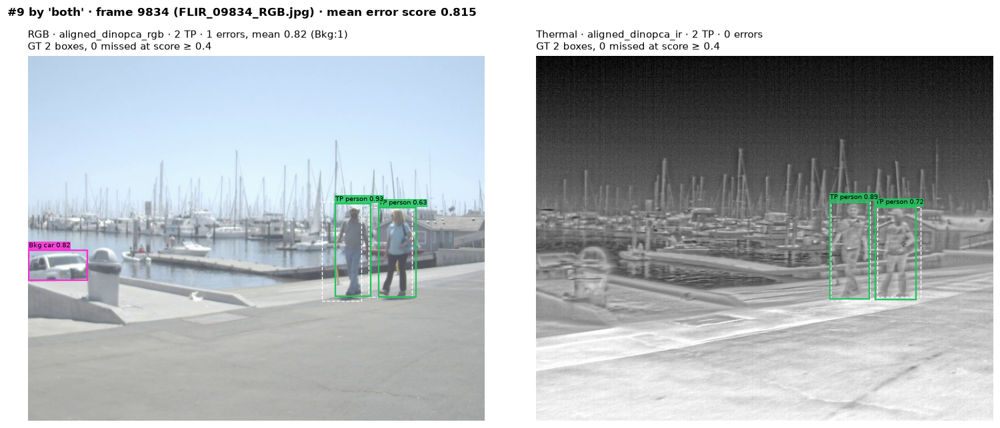

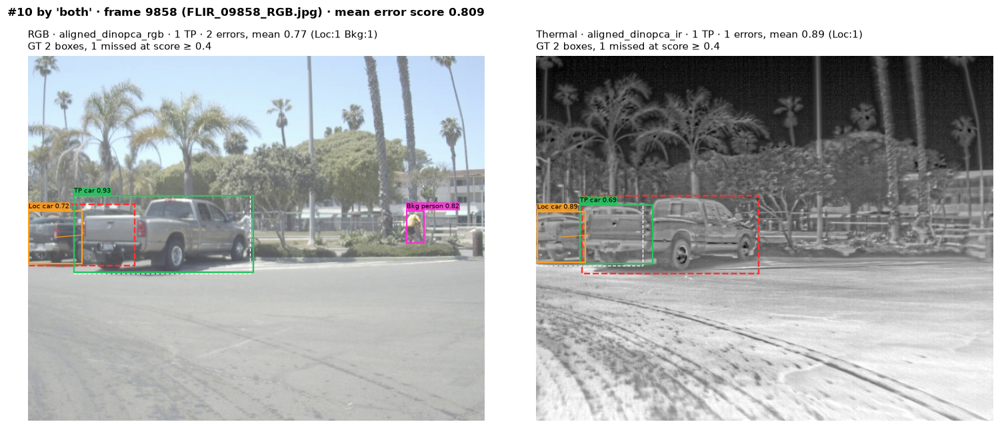

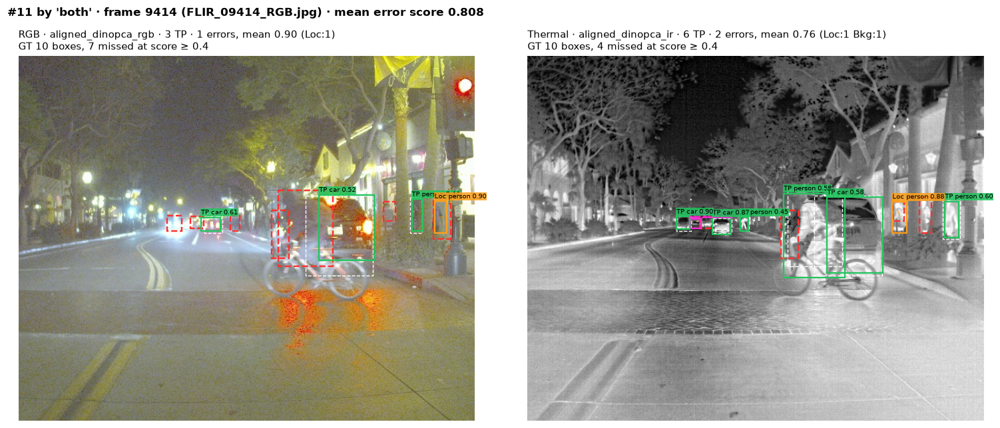

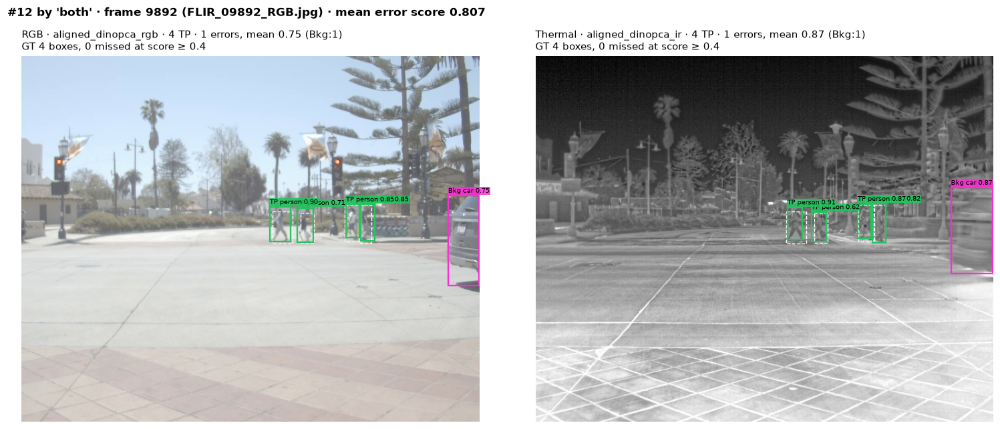

In [6]:
show_pairs(show_ranking_table("both"), "both")

### 3.2 Ranked by the RGB head's errors only

If the shared boxes fit thermal and not RGB, this should be dominated by confident **Loc** errors on the RGB side
whose thermal twin is a TP: the RGB head sees the object, the box sits next to it.

| rank | frame id | mean error score (rgb) | # errors | RGB errors (mean score) | RGB types | Thermal errors (mean score) | Thermal types |
|---|---|---|---|---|---|---|---|
| 1 | 9263 | 0.929 | 1 | 1 (0.93) | Loc:1 | 2 (0.68) | Loc:1 Bkg:1 |
| 2 | 9262 | 0.914 | 1 | 1 (0.91) | Loc:1 | 0 | – |
| 3 | 9414 | 0.899 | 1 | 1 (0.90) | Loc:1 | 2 (0.76) | Loc:1 Bkg:1 |
| 4 | 9332 | 0.895 | 1 | 1 (0.90) | Bkg:1 | 2 (0.64) | Bkg:2 |
| 5 | 9611 | 0.895 | 1 | 1 (0.90) | Loc:1 | 0 | – |
| 6 | 8956 | 0.875 | 1 | 1 (0.87) | Loc:1 | 2 (0.62) | Bkg:1 Dupe:1 |
| 7 | 9635 | 0.864 | 1 | 1 (0.86) | Bkg:1 | 2 (0.41) | Loc:1 Bkg:1 |
| 8 | 9992 | 0.849 | 1 | 1 (0.85) | Loc:1 | 1 (0.68) | Loc:1 |
| 9 | 9490 | 0.838 | 1 | 1 (0.84) | Bkg:1 | 1 (0.60) | Bkg:1 |
| 10 | 9733 | 0.836 | 1 | 1 (0.84) | Loc:1 | 5 (0.53) | Loc:2 Bkg:3 |
| 11 | 10016 | 0.831 | 1 | 1 (0.83) | Bkg:1 | 2 (0.53) | Bkg:2 |
| 12 | 8926 | 0.826 | 1 | 1 (0.83) | Loc:1 | 0 | – |

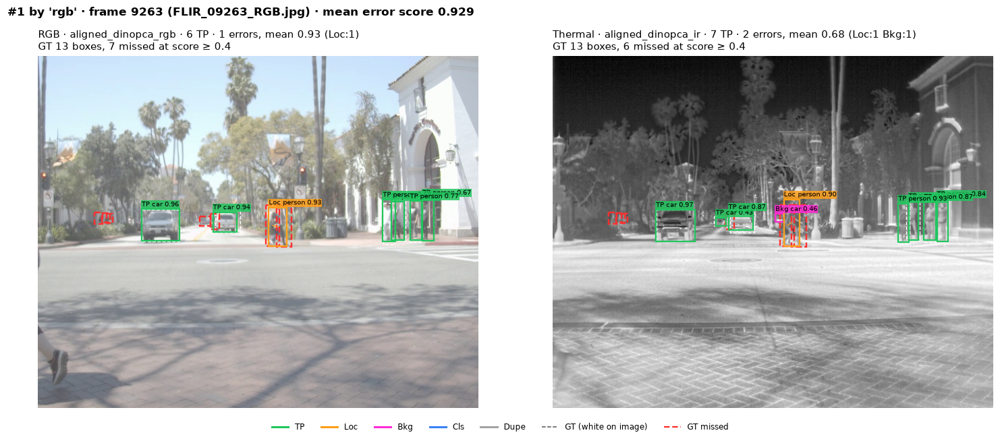

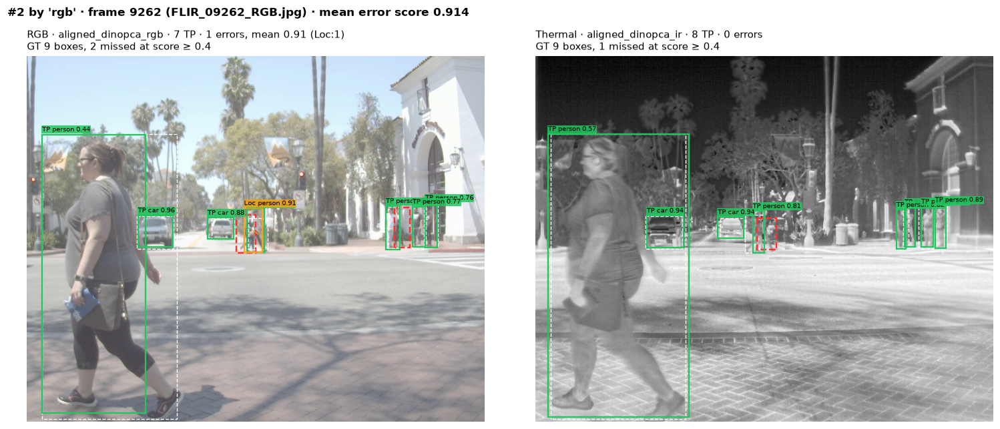

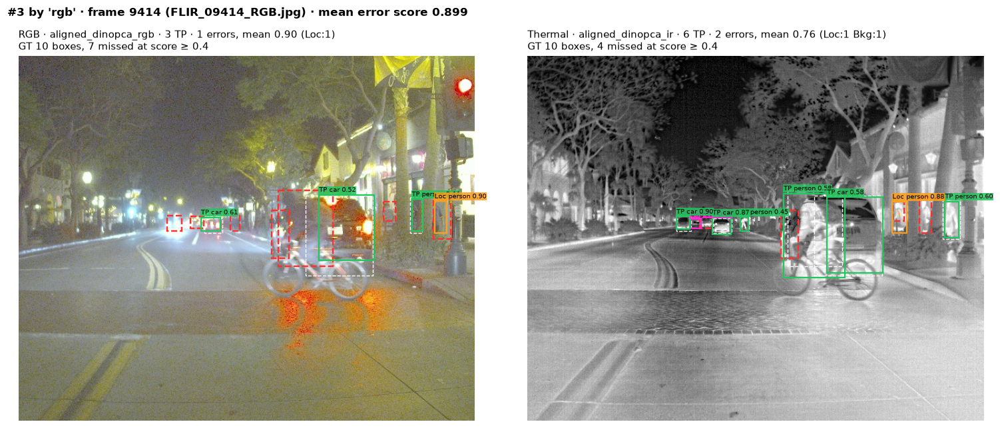

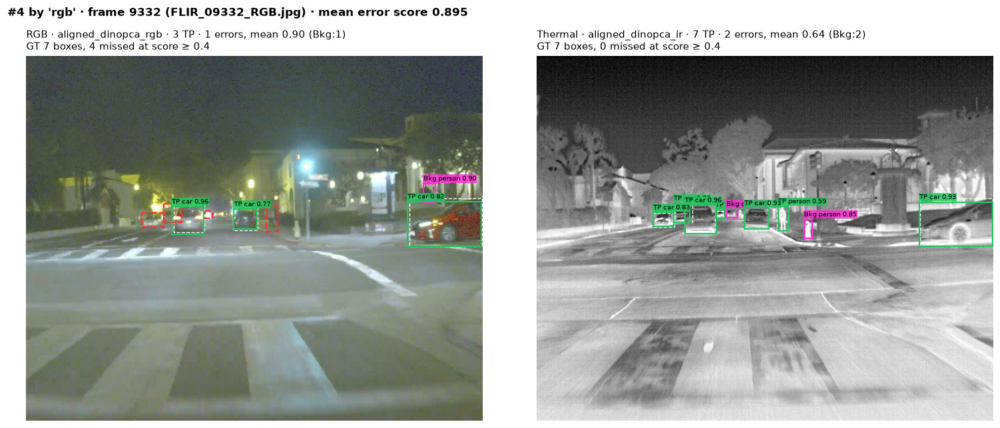

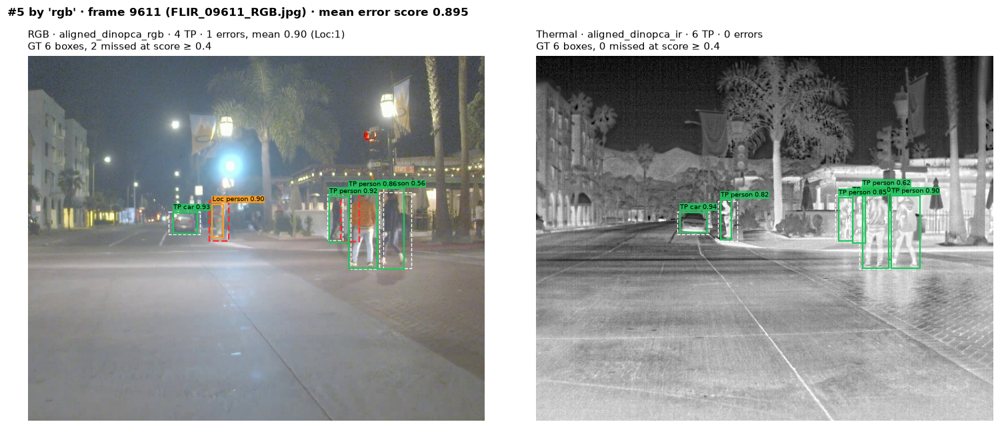

...

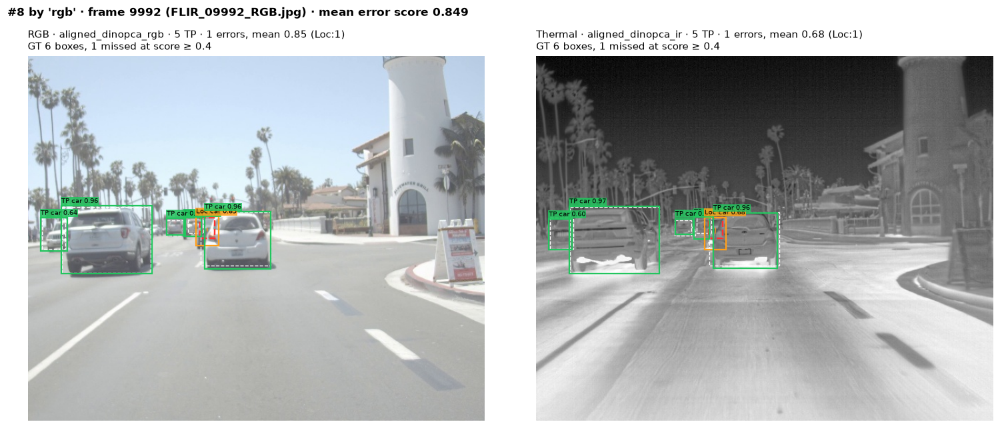

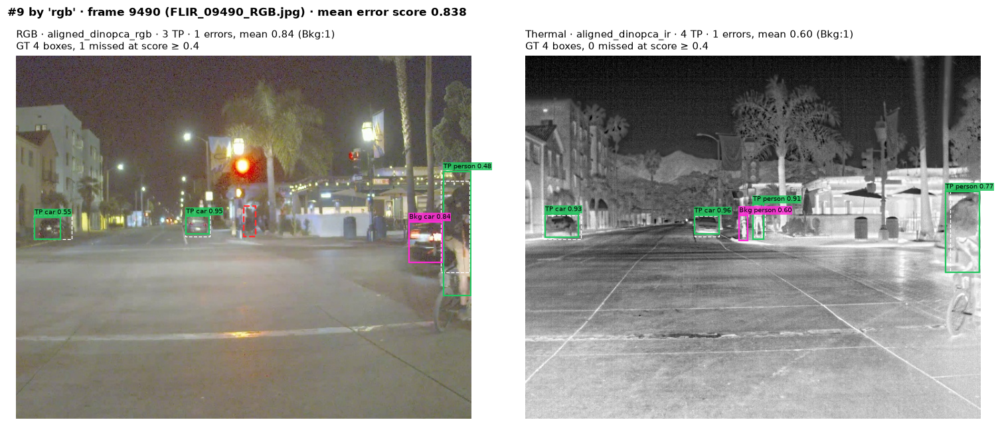

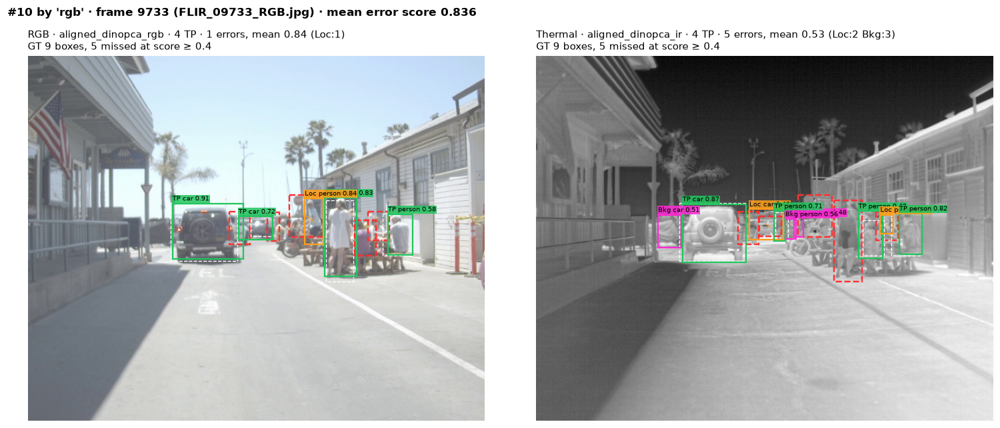

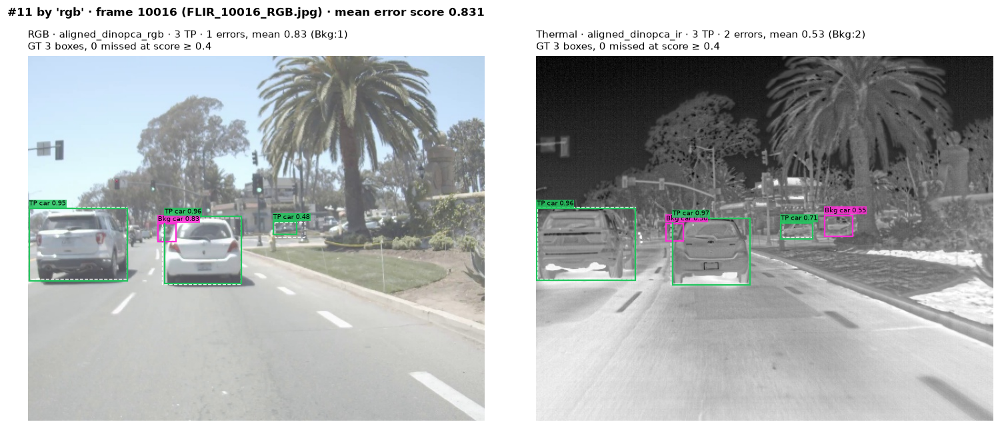

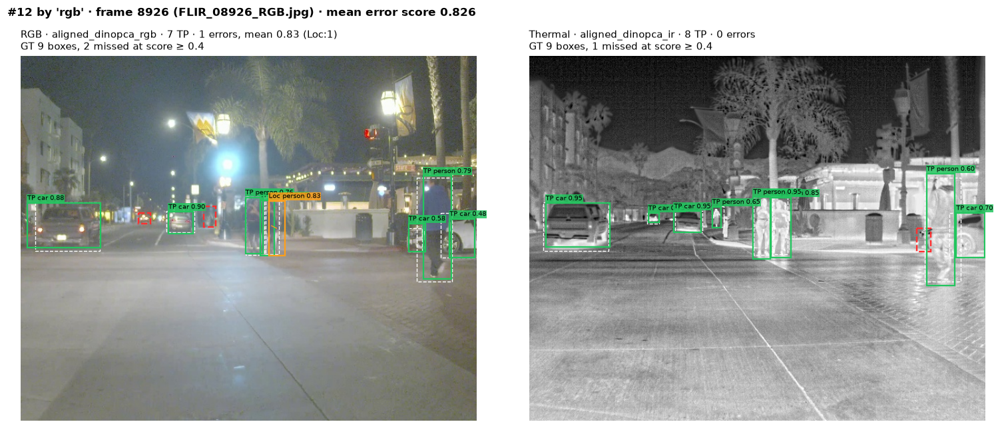

In [7]:
show_pairs(show_ranking_table("rgb"), "rgb")

### 3.3 Ranked by the thermal head's errors only

Confident thermal **Bkg** errors on an object that is clearly there (a warm pedestrian, a car) point to **missing
annotations**; those would also hurt RGB, but they are rarer to spot there.

| rank | frame id | mean error score (ir) | # errors | RGB errors (mean score) | RGB types | Thermal errors (mean score) | Thermal types |
|---|---|---|---|---|---|---|---|
| 1 | 9770 | 0.943 | 1 | 3 (0.71) | Loc:3 | 1 (0.94) | Loc:1 |
| 2 | 10135 | 0.909 | 1 | 0 | – | 1 (0.91) | Loc:1 |
| 3 | 9550 | 0.902 | 1 | 1 (0.58) | Loc:1 | 1 (0.90) | Loc:1 |
| 4 | 9327 | 0.896 | 1 | 2 (0.48) | Loc:1 Bkg:1 | 1 (0.90) | Bkg:1 |
| 5 | 9858 | 0.894 | 1 | 2 (0.77) | Loc:1 Bkg:1 | 1 (0.89) | Loc:1 |
| 6 | 10056 | 0.894 | 1 | 1 (0.41) | Bkg:1 | 1 (0.89) | Loc:1 |
| 7 | 9608 | 0.875 | 1 | 3 (0.68) | Loc:3 | 1 (0.88) | Cls:1 |
| 8 | 9615 | 0.874 | 1 | 5 (0.81) | Loc:4 Bkg:1 | 1 (0.87) | Bkg:1 |
| 9 | 9892 | 0.867 | 1 | 1 (0.75) | Bkg:1 | 1 (0.87) | Bkg:1 |
| 10 | 9966 | 0.862 | 1 | 4 (0.53) | Loc:1 Bkg:3 | 1 (0.86) | Dupe:1 |
| 11 | 9549 | 0.855 | 1 | 0 | – | 1 (0.85) | Loc:1 |
| 12 | 9907 | 0.855 | 1 | 4 (0.65) | Loc:3 Bkg:1 | 1 (0.85) | Bkg:1 |

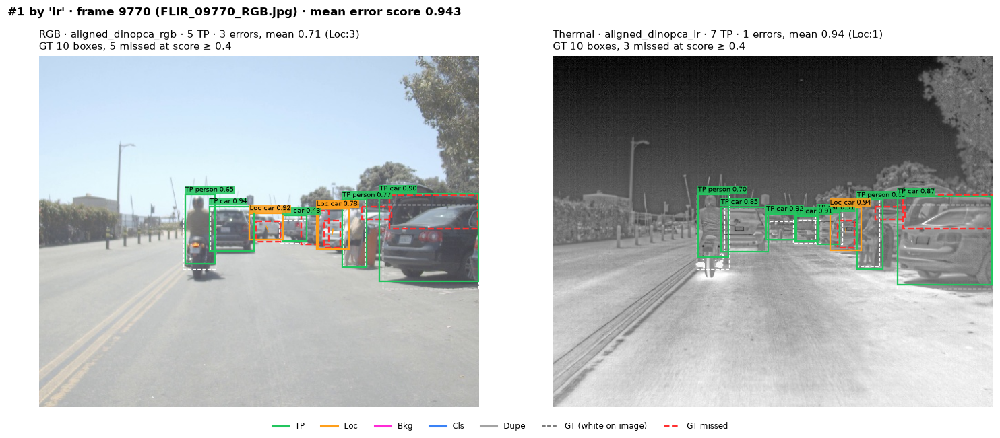

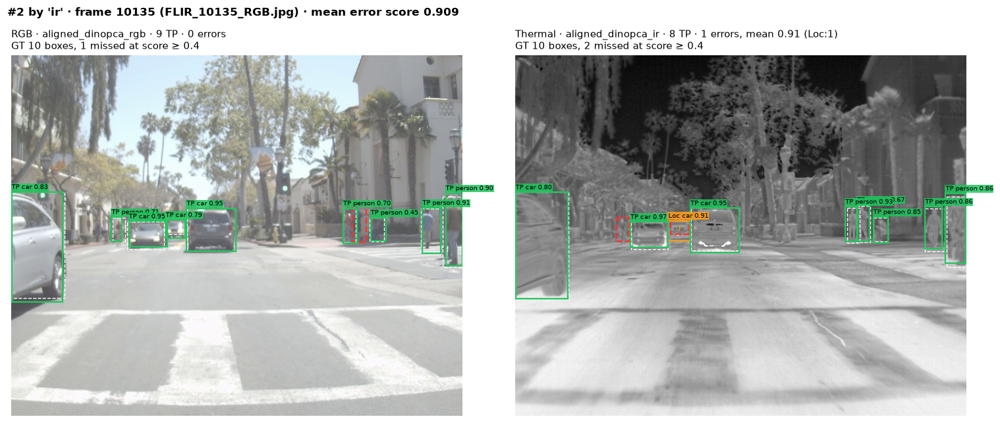

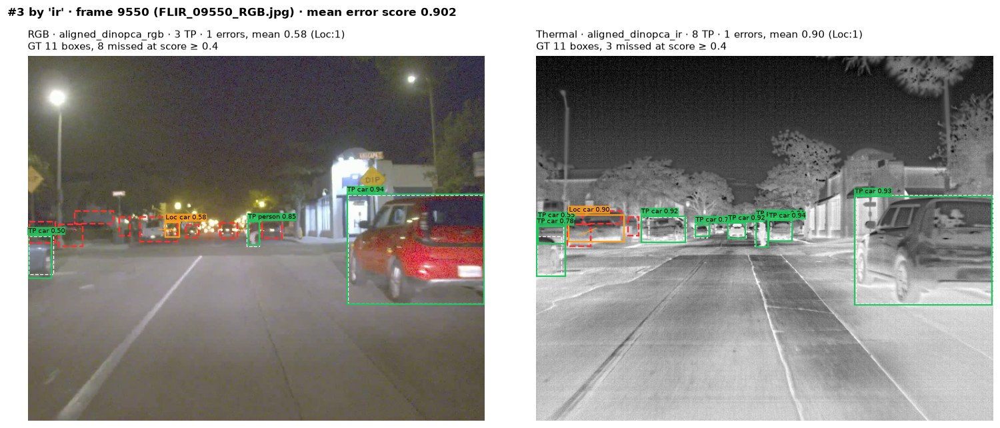

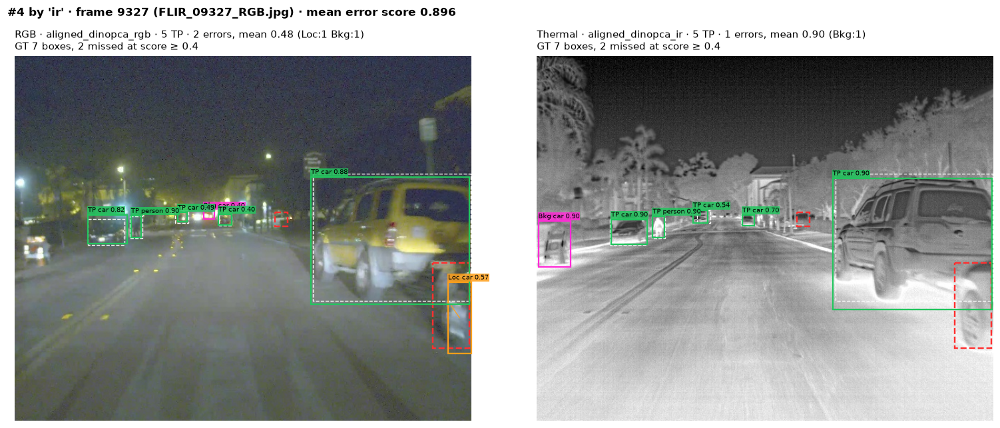

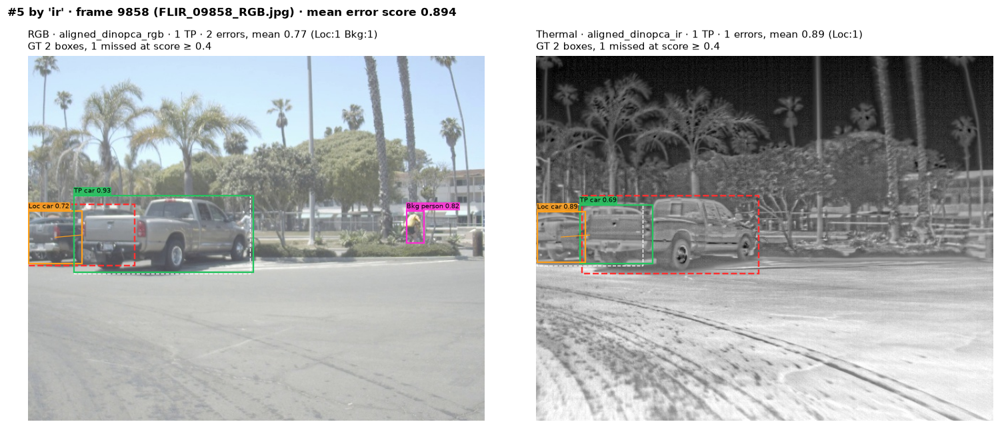

...

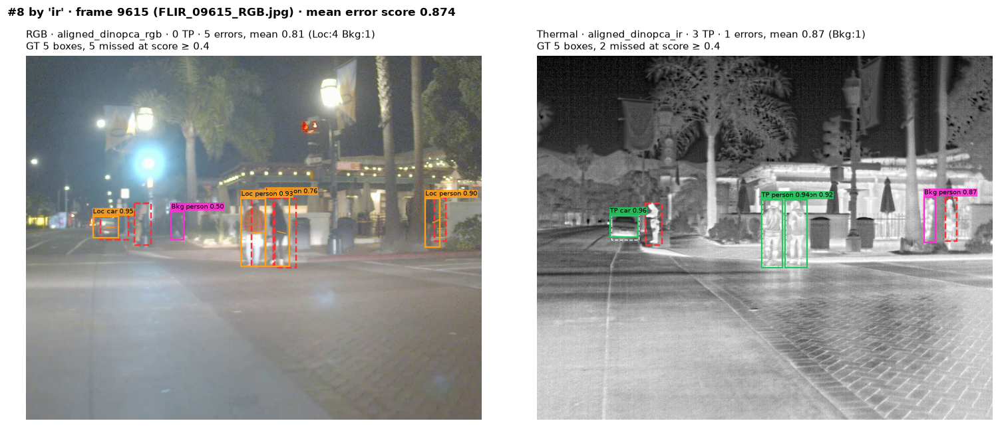

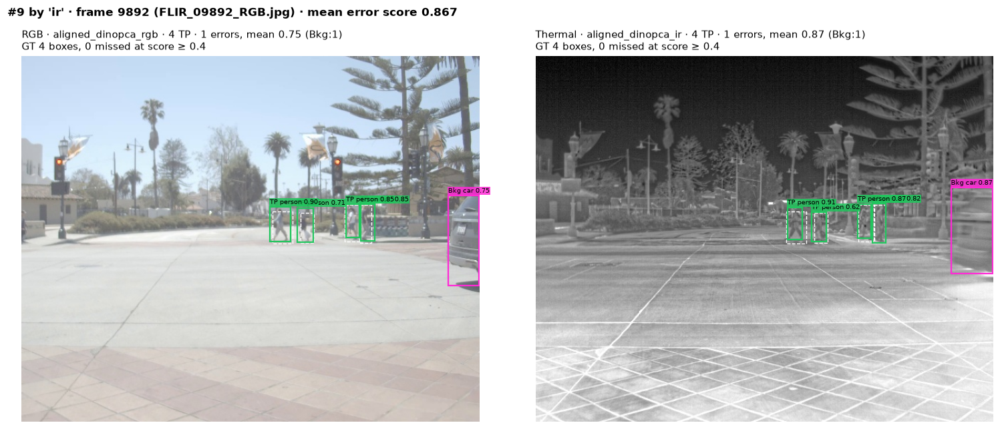

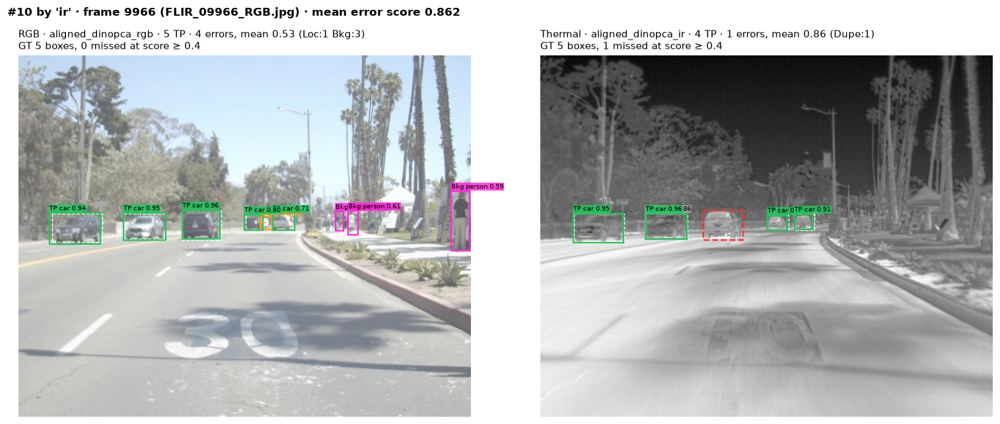

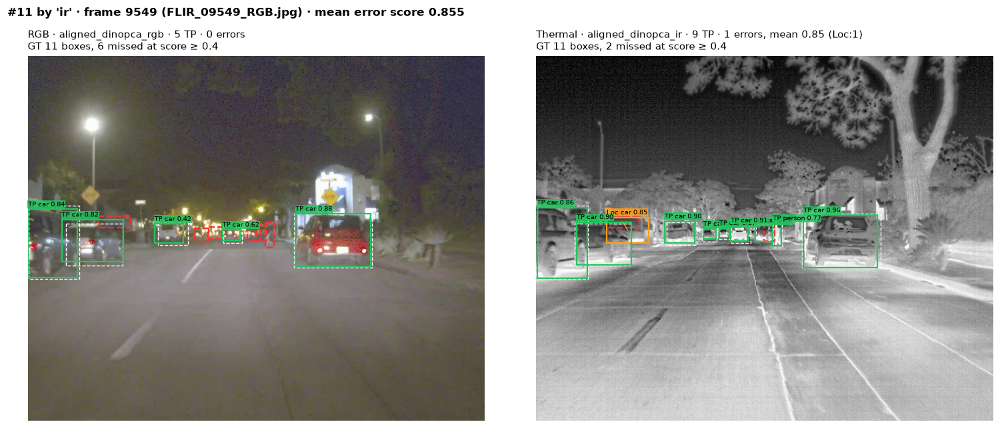

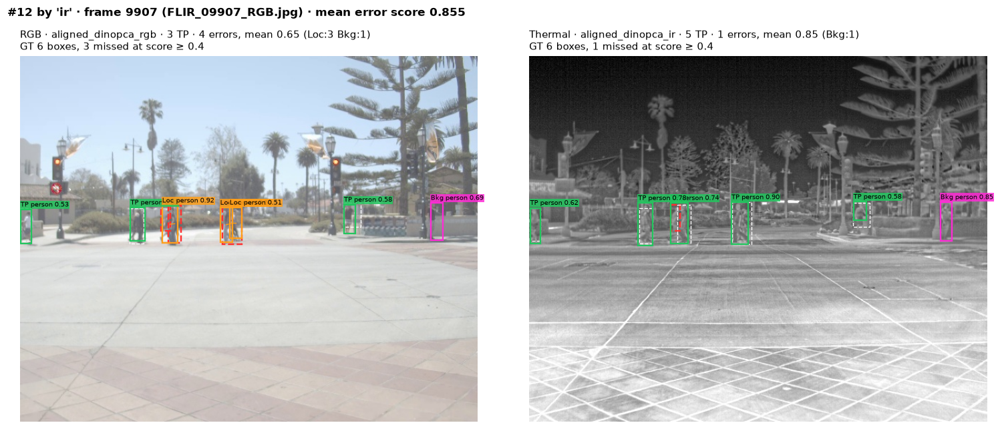

In [8]:
show_pairs(show_ranking_table("ir"), "ir")

## 4. Observations

*Pending: written once the F19 detection files are in and the figures above have been looked at.*

Things to check while looking:

1. **Loc on RGB, TP on thermal, same object** → the RGB box offset (direction and size; does it grow for near,
   large objects, as parallax would?).
2. **Bkg on both heads at the same place** → very likely a missing annotation (both sensors agree there is an object).
3. **Confident Cls errors** → wrong class labels (person ↔ car), or riders/bicycles (mapped to background).
4. Errors on the RGB black border, or objects visible only in one modality (night, glare).

## 5. AP50 per class, day vs night, every backbone

For each backbone, the **RGB head on the RGB frames** and the **thermal head on the thermal frames** (each detector in
its own domain), AP50 for car and for person, split by time of day.

Day/night comes from the manual clip segmentation of the test split (`aligned_test_day_night_clips.ipynb`,
`$IRWM_OUTPUT_ROOT/annotations/aligned_test_segments.json`), so this section needs `SPLIT = "test"`. AP50 is computed
with the same COCO matching as `tide()` / `coco_map` (IoU 0.5, 101-point AP, ≤ 100 detections per frame and class)
on the subset of frames, with GT and detections restricted to those frames. On the full split it must reproduce the
per-class AP50 recorded in the F19 run; the cell checks that before splitting.

In [9]:
from irwm.eval.tide import _mean

assert SPLIT == "test", "day/night labels exist only for the test split"
SEG_FILE = output_root() / "annotations" / "aligned_test_segments.json"
seg = json.loads(SEG_FILE.read_text())
TOD = ["day", "night"]
TOD_IDS = {t: set() for t in TOD}
all_ids = np.array(IMG_IDS)
for c in seg["segments"]:
    TOD_IDS[c["time_of_day"]] |= set(all_ids[(all_ids >= c["start_id"]) & (all_ids <= c["end_id"])].tolist())
assert TOD_IDS["day"].isdisjoint(TOD_IDS["night"]) and TOD_IDS["day"] | TOD_IDS["night"] == set(IMG_IDS)

BACKBONES = sorted({h.removeprefix("aligned_").rsplit("_", 1)[0] for h in RUN["heads"]},
                   key=["dinopca", "dino3072", "mae"].index)
CAT_ID = {"person": 1, "car": 2}


def load_dets(head, mod):
    entry = RUN["detections"][head][mod]
    raw = (OUT / entry["path"]).read_bytes()
    assert hashlib.sha256(raw).hexdigest() == entry["sha256"], entry["path"]
    obj = json.loads(gzip.decompress(raw))
    assert (obj["head"], obj["modality"], obj["split"]) == (head, mod, SPLIT), entry["path"]
    return obj["detections"]


def ap50_per_class(gt, dets, ids=None):
    # COCO AP50 per category id on the frames `ids` (all frames if None); -1 for a class with no GT there.
    if ids is not None:
        gt = {**gt, "images": [im for im in gt["images"] if im["id"] in ids],
              "annotations": [a for a in gt["annotations"] if a["image_id"] in ids]}
        dets = [d for d in dets if d["image_id"] in ids]
    data = _Data(gt, dets, MAX_DETS)
    ap, _ = _evaluate(data.gt, data.dt, data.img_ids, data.cats, POS_THR)
    return ap


AP = {}  # (backbone, "rgb"|"ir", tod) -> {cat_id: AP50}
for bb in BACKBONES:
    for m in MODS:
        head, mod = f"aligned_{bb}_{m}", SPLIT_MOD[m]
        dets = load_dets(head, mod)
        full = ap50_per_class(GT[m], dets)
        cell = RUN["cells"][head][mod]
        for name, cid in CAT_ID.items():  # same matching as the run's coco_map
            assert abs(full[cid] - cell[f"AP50_{name}"]) < 1e-9, (head, name, full[cid], cell[f"AP50_{name}"])
        for t in TOD:
            AP[(bb, m, t)] = ap50_per_class(GT[m], dets, TOD_IDS[t])
print(f"per-class AP50 on the full split matches the F19 run for all {len(BACKBONES) * len(MODS)} heads: ok")

# frames and GT boxes per time of day (one shared annotation, so the same for both modalities)
n_box = {t: Counter(a["category_id"] for a in GT["ir"]["annotations"] if a["image_id"] in TOD_IDS[t]) for t in TOD}
display(Markdown("\n".join(["| | frames | GT person | GT car |", "|---|---|---|---|"]
                           + [f"| {t} | {len(TOD_IDS[t])} | {n_box[t][1]} | {n_box[t][2]} |" for t in TOD])))

COMBOS = [(m, t) for m in ("ir", "rgb") for t in TOD]
fmt = lambda v: f"{v:.3f}" if v > -1 else "–"
hdr = ["backbone"] + [f"{MOD_LABEL[m]} {t} · {c}" for m, t in COMBOS for c in ("car", "person")]
rows = [[f"`{bb}`"] + [fmt(AP[(bb, m, t)][CAT_ID[c]]) for m, t in COMBOS for c in ("car", "person")]
        for bb in BACKBONES]
display(Markdown(f"**AP50, aligned {SPLIT}, each head on its own modality** (RGB head → RGB frames, "
                 f"thermal head → thermal frames)"))
display(Markdown("\n".join(["| " + " | ".join(hdr) + " |", "|" + "---|" * len(hdr)]
                           + ["| " + " | ".join(r) + " |" for r in rows])))

per-class AP50 on the full split matches the F19 run for all 6 heads: ok


| | frames | GT person | GT car |
|---|---|---|---|
| day | 702 | 2900 | 2818 |
| night | 311 | 1207 | 1306 |

**AP50, aligned test, each head on its own modality** (RGB head → RGB frames, thermal head → thermal frames)

| backbone | Thermal day · car | Thermal day · person | Thermal night · car | Thermal night · person | RGB day · car | RGB day · person | RGB night · car | RGB night · person |
|---|---|---|---|---|---|---|---|---|
| `dinopca` | 0.827 | 0.715 | 0.910 | 0.836 | 0.820 | 0.682 | 0.663 | 0.529 |
| `dino3072` | 0.842 | 0.728 | 0.909 | 0.830 | 0.827 | 0.700 | 0.678 | 0.540 |
| `mae` | 0.810 | 0.696 | 0.896 | 0.802 | 0.791 | 0.663 | 0.637 | 0.480 |

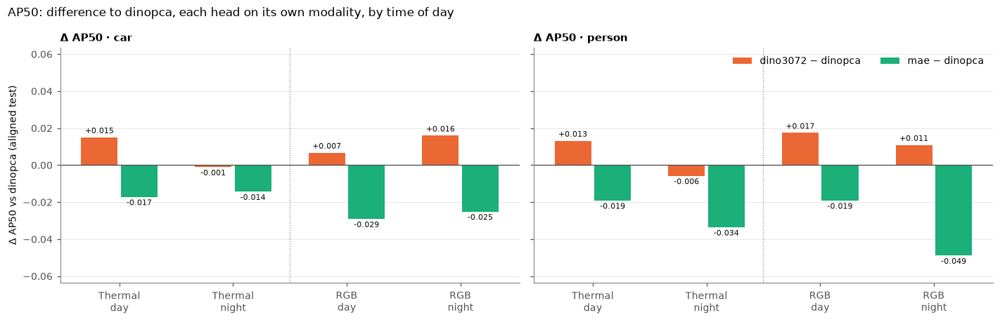

In [10]:
# Difference to the PCA backbone, per bucket: (dino3072 - dinopca) and (mae - dinopca). One panel per class;
# groups = modality x time of day. Bars keep each backbone's colour from before; above 0 = better than dinopca.
BB_COLOR = dict(zip(["dinopca", "dino3072", "mae"], ["#2a78d6", "#eb6834", "#1baf7a"]))  # categorical slots 1-3
REF = "dinopca"
GROUPS = [(m, t) for m in ("ir", "rgb") for t in TOD]
STYLE = {"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
         "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.edgecolor": "#8a8984", "xtick.color": "#52514e",
         "ytick.color": "#52514e"}


def plot_deltas(ap, metric):
    # ap: (backbone, "rgb"|"ir", tod) -> {cat_id: value}; plots value(bb) - value(REF) per bucket and class
    others = [bb for bb in BACKBONES if bb != REF]
    width, x = 0.7 / len(others), np.arange(len(GROUPS))
    delta = {(bb, c): np.array([ap[(bb, m, t)][CAT_ID[c]] - ap[(REF, m, t)][CAT_ID[c]] for m, t in GROUPS])
             for bb in others for c in CAT_ID}
    lim = max(np.abs(v).max() for v in delta.values()) * 1.3
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
        for ax, cname in zip(axes, ("car", "person")):
            for k, bb in enumerate(others):
                v = delta[(bb, cname)]
                xs = x + (k - (len(others) - 1) / 2) * width
                ax.bar(xs, v, width * 0.92, color=BB_COLOR[bb], label=f"{bb} − {REF}")
                for xi, vi in zip(xs, v):
                    ax.text(xi, vi + np.sign(vi or 1) * lim * 0.02, f"{vi:+.3f}", ha="center",
                            va="bottom" if vi >= 0 else "top", fontsize=7, color="#0b0b0b")
            ax.axhline(0, color="#52514e", lw=0.9)
            ax.axvline(1.5, color="#8a8984", lw=0.8, ls=":")  # thermal | RGB
            ax.set_xticks(x, [f"{MOD_LABEL[m]}\n{t}" for m, t in GROUPS])
            ax.grid(axis="x", visible=False)
            ax.set_ylim(-lim, lim)
            ax.set_title(f"Δ {metric} · {cname}", loc="left", fontweight="bold")
        axes[0].set_ylabel(f"Δ {metric} vs {REF} (aligned {SPLIT})")
        axes[1].legend(frameon=False, loc="upper right", ncol=len(others))
        fig.suptitle(f"{metric}: difference to {REF}, each head on its own modality, by time of day",
                     x=0.01, ha="left", fontsize=11)
        fig.tight_layout()
        plt.show()


plot_deltas(AP, "AP50")

## 6. AP[0.5:0.95] per class, day vs night, every backbone

Same buckets and heads as §5, with the COCO primary metric: AP averaged over IoU thresholds 0.50, 0.55, …, 0.95
(each threshold matched separately, as `COCOeval`; area all, ≤ 100 detections per frame and class). The cell first
checks that on the full split this reproduces the per-class AP (`AP_person`, `AP_car`) recorded in the F19 run.
Because AP[0.5:0.95] rewards tight boxes, it is the metric where a box that fits thermal but not RGB shows up most.

per-class AP[0.5:0.95] on the full split matches the F19 run for all 6 heads: ok


**AP[0.5:0.95], aligned test, each head on its own modality**

| backbone | Thermal day · car | Thermal day · person | Thermal night · car | Thermal night · person | RGB day · car | RGB day · person | RGB night · car | RGB night · person |
|---|---|---|---|---|---|---|---|---|
| `dinopca` | 0.510 | 0.321 | 0.539 | 0.389 | 0.492 | 0.284 | 0.309 | 0.194 |
| `dino3072` | 0.523 | 0.331 | 0.542 | 0.390 | 0.506 | 0.302 | 0.334 | 0.203 |
| `mae` | 0.508 | 0.316 | 0.544 | 0.375 | 0.479 | 0.279 | 0.299 | 0.175 |

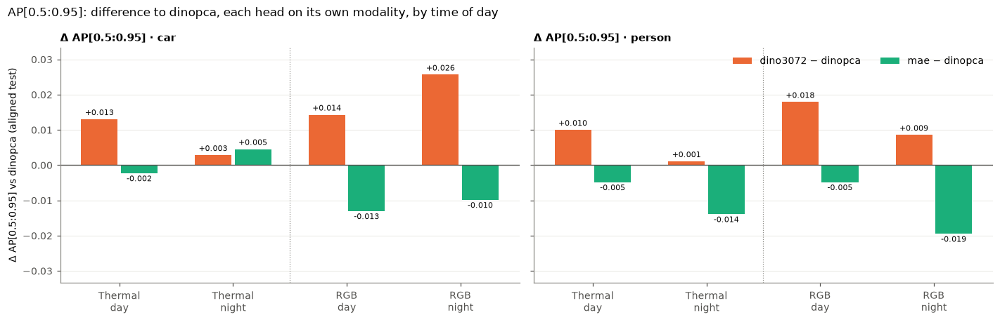

In [11]:
IOU_THRS = np.linspace(0.5, 0.95, 10)


def ap_coco_per_class(gt, dets, ids=None):
    # COCO AP[0.5:0.95] per category id on the frames `ids` (all frames if None).
    if ids is not None:
        gt = {**gt, "images": [im for im in gt["images"] if im["id"] in ids],
              "annotations": [a for a in gt["annotations"] if a["image_id"] in ids]}
        dets = [d for d in dets if d["image_id"] in ids]
    data = _Data(gt, dets, MAX_DETS)
    per_thr = [_evaluate(data.gt, data.dt, data.img_ids, data.cats, thr)[0] for thr in IOU_THRS]
    return {c: float(np.mean([a[c] for a in per_thr])) if per_thr[0][c] > -1 else -1.0 for c in data.cats}


AP_COCO = {}  # (backbone, "rgb"|"ir", tod) -> {cat_id: AP[0.5:0.95]}
for bb in BACKBONES:
    for m in MODS:
        head, mod = f"aligned_{bb}_{m}", SPLIT_MOD[m]
        dets = load_dets(head, mod)
        full = ap_coco_per_class(GT[m], dets)
        cell = RUN["cells"][head][mod]
        for name, cid in CAT_ID.items():  # same matching as the run's coco_map
            assert abs(full[cid] - cell[f"AP_{name}"]) < 1e-6, (head, name, full[cid], cell[f"AP_{name}"])
        for t in TOD:
            AP_COCO[(bb, m, t)] = ap_coco_per_class(GT[m], dets, TOD_IDS[t])
print(f"per-class AP[0.5:0.95] on the full split matches the F19 run for all {len(BACKBONES) * len(MODS)} heads: ok")

hdr = ["backbone"] + [f"{MOD_LABEL[m]} {t} · {c}" for m, t in COMBOS for c in ("car", "person")]
rows = [[f"`{bb}`"] + [fmt(AP_COCO[(bb, m, t)][CAT_ID[c]]) for m, t in COMBOS for c in ("car", "person")]
        for bb in BACKBONES]
display(Markdown(f"**AP[0.5:0.95], aligned {SPLIT}, each head on its own modality**"))
display(Markdown("\n".join(["| " + " | ".join(hdr) + " |", "|" + "---|" * len(hdr)]
                           + ["| " + " | ".join(r) + " |" for r in rows])))

plot_deltas(AP_COCO, "AP[0.5:0.95]")